# Milestone 9 - FastAPI server & web interface

`api/server.py` exposes the pipeline as a REST API (`POST /api/query`, `GET /api/health`, rendered PDF pages for the citation drawer) and serves the single-page UI in `api/static/index.html`. This notebook starts the server, exercises every endpoint and shuts it down again. To use the UI interactively run `.venv/bin/uvicorn api.server:app --port 8000` and open http://127.0.0.1:8000.

In [1]:
import os, sys, json, time, warnings, pathlib
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
from rag import config

In [2]:
import subprocess, requests
PORT = 8765
srv = subprocess.Popen([sys.executable, "-m", "uvicorn", "api.server:app", "--port", str(PORT), "--log-level", "warning"],
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
base = f"http://127.0.0.1:{PORT}"
for _ in range(240):
    try:
        if requests.get(base + "/api/health", timeout=1).ok: break
    except requests.RequestException: pass
    time.sleep(1)
requests.get(base + "/api/health").json()

{'qdrant': True,
 'llm': True,
 'pipeline': True,
 'llm_model': 'phi-4-mini-lora',
 'reranker': './models/bge-reranker-large-finetuned'}

In [3]:
t = time.time()
resp = requests.post(base + "/api/query", json={"question": "What is the hotel cap per night outside capital cities?"}).json()
print(f"HTTP round trip {time.time() - t:.2f}s")
{k: resp[k] for k in ("status", "answer", "citations", "regenerations", "timings_s")}

HTTP round trip 0.72s


{'status': 'verified',
 'answer': 'Hotel accommodation is capped at EUR 210 per night outside capital cities [HIS_Employee_Handbook_2026.pdf, p. 4].',
 'citations': [{'source': 1,
   'doc': 'HIS_Employee_Handbook_2026.pdf',
   'page': 4,
   'loc': 'p. 4'}],
 'regenerations': 0,
 'timings_s': {'retrieval': 0.01986787499845377,
  'rerank': 0.3166278749995399,
  'generation': 0.30641758300043875,
  'verification': 0.07673929199881968,
  'total': 0.7196700409986079}}

In [4]:
naive = requests.post(base + "/api/query", json={"question": "What is the hotel cap per night outside capital cities?", "mode": "naive"}).json()
{k: naive[k] for k in ("status", "answer", "citations")}

{'status': 'unverified_baseline',
 'answer': 'Hotel accommodation is capped at EUR 210 per night outside capital cities [HIS_Employee_Handbook_2026.pdf, p. 4].',
 'citations': [{'source': 1,
   'doc': 'HIS_Employee_Handbook_2026.pdf',
   'page': 4,
   'loc': 'p. 4'}]}

### Citation drawer support: page rendering

200 image/png 56263 bytes


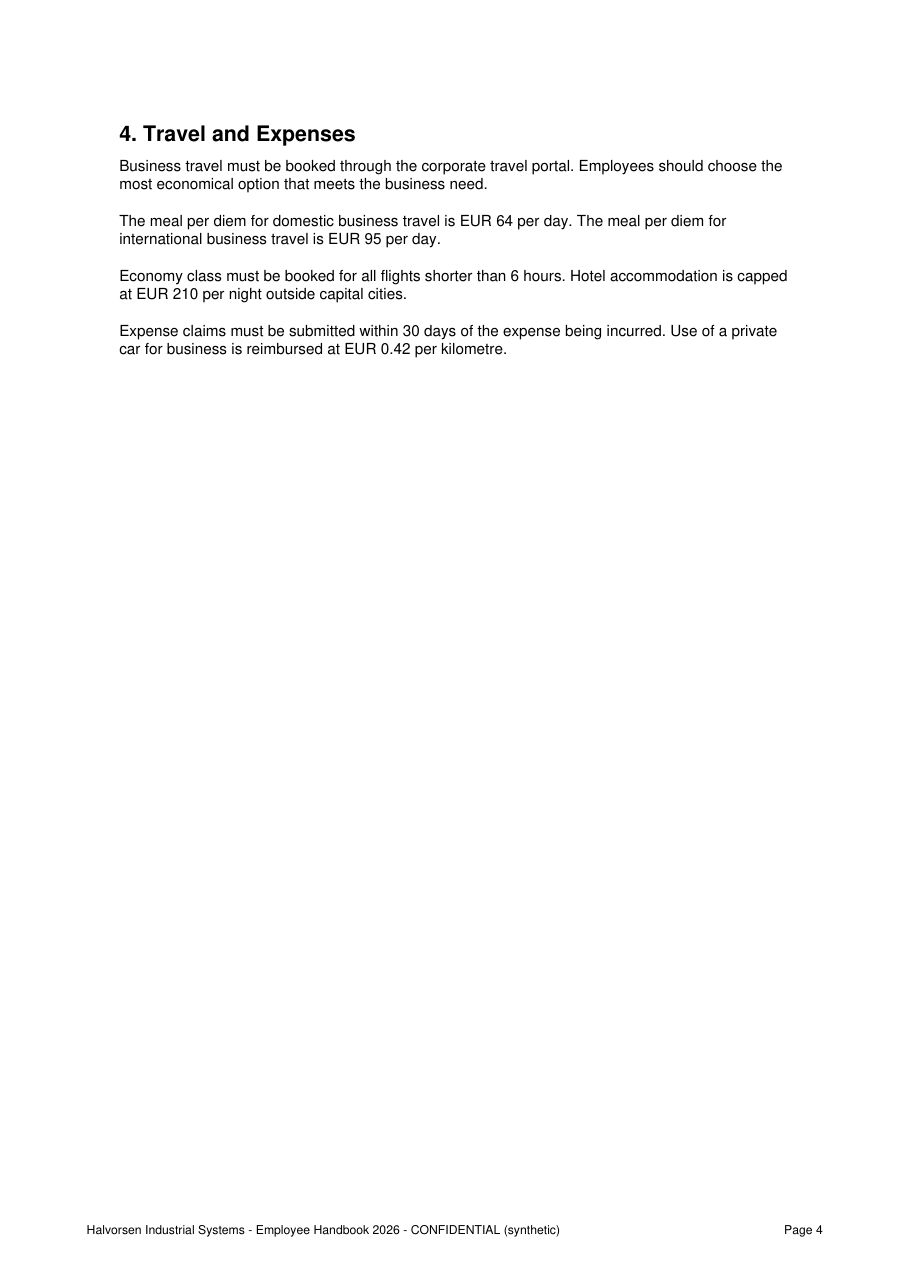

In [5]:
from IPython.display import Image, display
c = resp["citations"][0]
img = requests.get(f"{base}/api/documents/{c['doc']}/page/{c['page']}.png")
print(img.status_code, img.headers["content-type"], len(img.content), "bytes")
display(Image(img.content, width=420))

UI page: 200 | documents: ['CU4_Controller_Firmware_Release_Notes.docx', 'CU4_Known_Issues.md', 'HIS_Annual_Operations_Report_FY2025.pdf', 'HIS_Employee_Handbook_2026.pdf'] ...
input validation: 422
path traversal blocked: 404


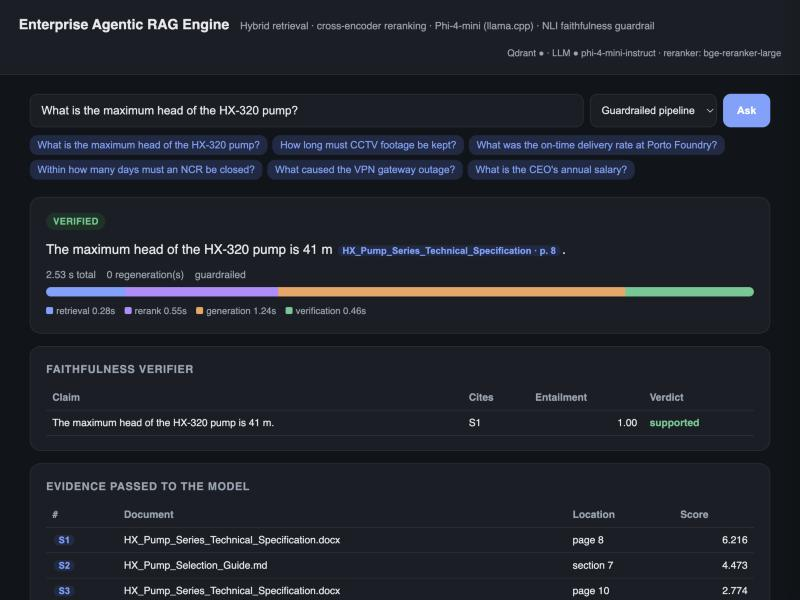

In [6]:
print("UI page:", requests.get(base + "/").status_code, "| documents:", requests.get(base + "/api/documents").json()[:4], "...")
print("input validation:", requests.post(base + "/api/query", json={"question": ""}).status_code)
print("path traversal blocked:", requests.get(base + "/api/documents/..%2F..%2Frag%2Fconfig.py/raw").status_code)
shot = config.ARTIFACT_DIR / "ui_screenshot.jpg"
if shot.exists(): display(Image(str(shot), width=900))

In [7]:
srv.terminate(); srv.wait(10); print("server stopped")

server stopped
